In [27]:
import numpy as np
import matplotlib.pyplot as plt
import os
import Functions as register

Loading files …
  ✓  452: loaded angles_shifted_21MAR26_og_ptycho_Gamma45_all_scans_failed_psd.txt
  ✓  452: loaded unaligned_mean__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded unaligned_var__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded aligned_mean__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded aligned_var__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded fid_amp_neg__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded fid_amp_pos__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded angles_shifted_16MAR26_og_ptycho_Gamma90_all_scans_failed_psd.txt
  ✓  452: loaded unaligned_mean__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded unaligned_var__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded aligned_mean__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded aligned_var__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded fid_amp_neg__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓

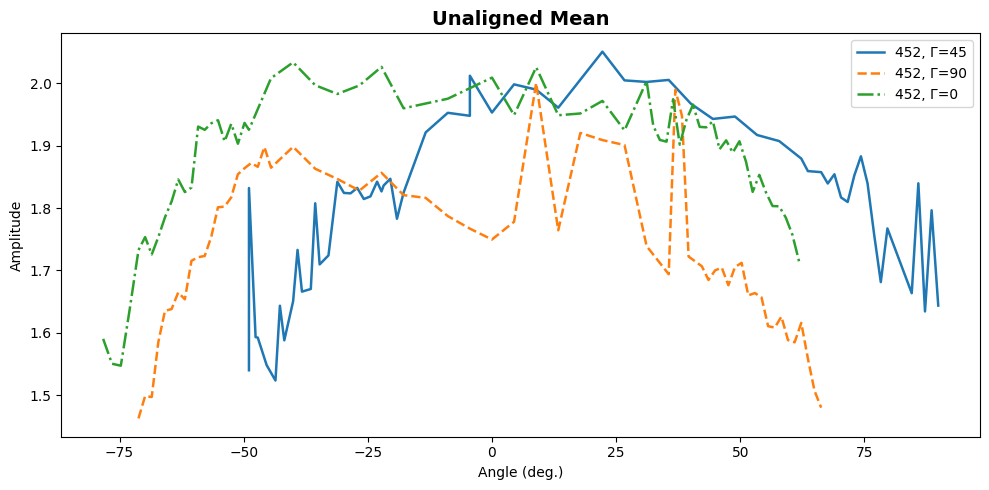

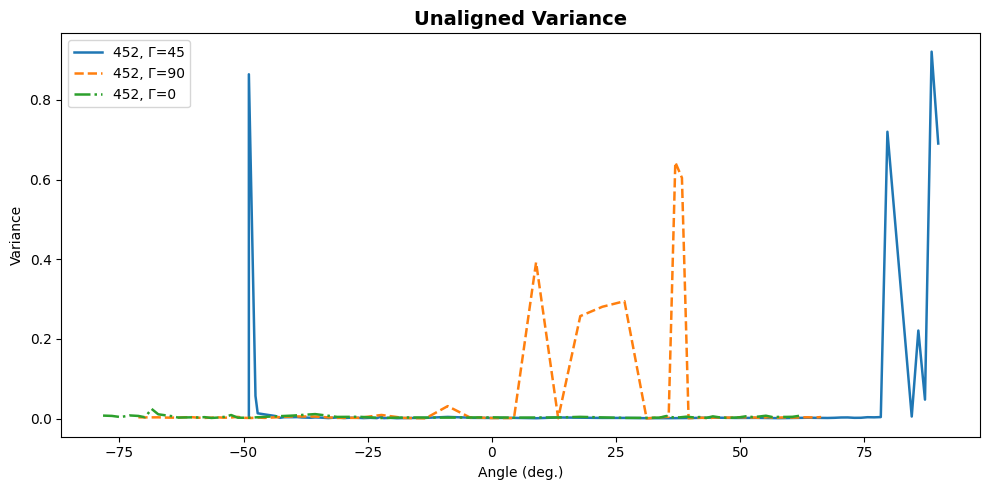

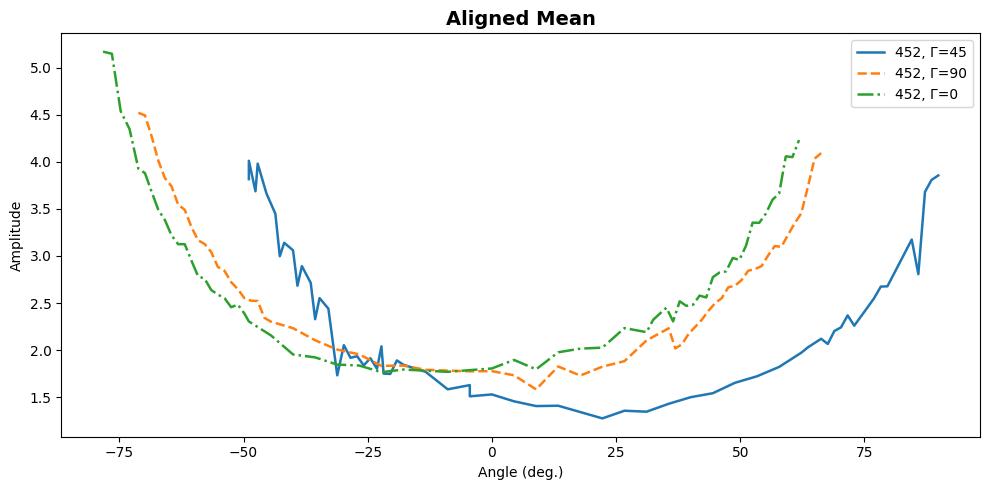

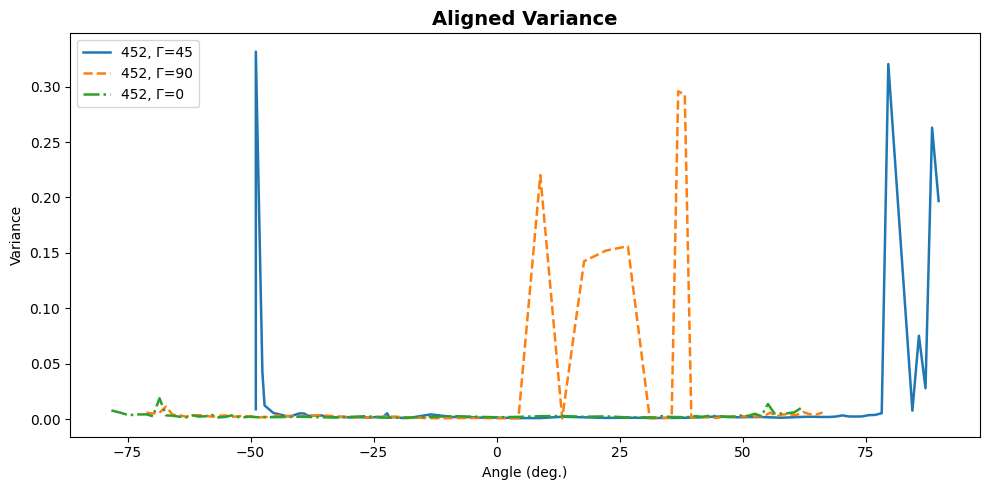

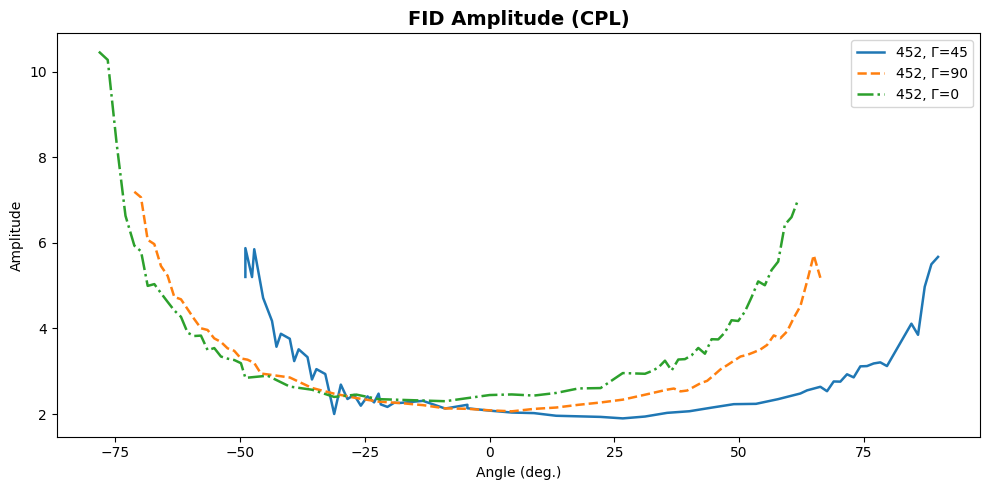

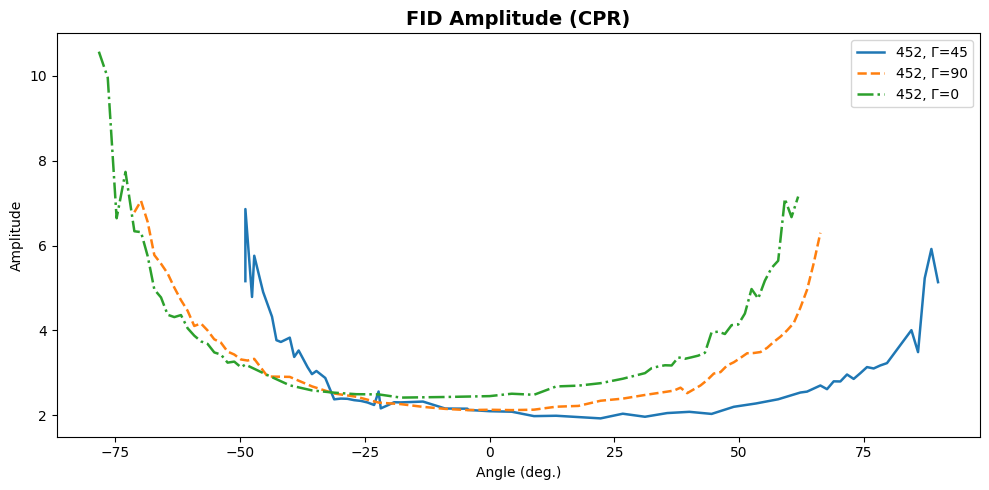

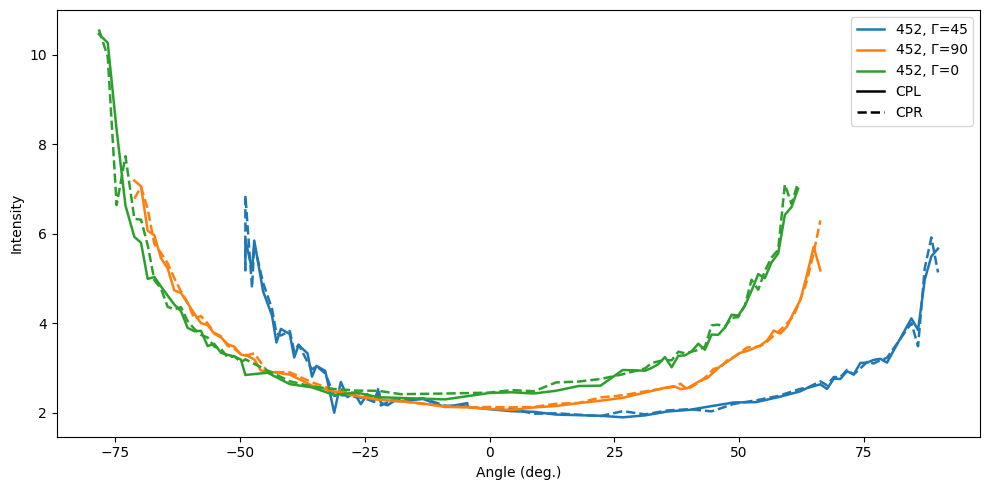


Done.


In [37]:


# ── Configuration ────────────────────────────────────────────────────────────

sample_id = [
    {"sample": "452", "date": "_21MAR26_og_ptycho", "Gamma": "Gamma45", "modifier": "all_scans_failed_psd"},
    {"sample": "452", "date": "_16MAR26_og_ptycho", "Gamma": "Gamma90", "modifier": "all_scans_failed_psd"},
    {"sample": "452", "date": "_16MAR26_og_ptycho", "Gamma": "Gamma0", "modifier": "all_scans_failed_psd"},
    # {"sample": "665", "date": "_3AUG25_check_saturation_n50", "Gamma": "Gamma0", "modifier": "test"},
    # {"sample": "665", "date": "_5AUG25_check_saturation_n50", "Gamma": "Gammaneg45", "modifier": "test"},
]

file_keys = [
    "unaligned_mean",
    "unaligned_var",
    "aligned_mean",
    "aligned_var",
    "fid_amp_neg",
    "fid_amp_pos"
]

plot_meta = {
    "unaligned_mean": {"title": "Unaligned Mean",           "ylabel": "Amplitude"},
    "unaligned_var":  {"title": "Unaligned Variance",        "ylabel": "Variance"},
    "aligned_mean":   {"title": "Aligned Mean",              "ylabel": "Amplitude"},
    "aligned_var":    {"title": "Aligned Variance",          "ylabel": "Variance"},
    "fid_amp_neg":    {"title": "FID Amplitude (CPL)",       "ylabel": "Amplitude"},
    "fid_amp_pos":    {"title": "FID Amplitude (CPR)",       "ylabel": "Amplitude"}
}


# ── Load data ────────────────────────────────────────────────────────────────
def load_sample(sample_id: dict) -> dict:
    sample, date, Gamma, modifier = sample_id["sample"], sample_id["date"], sample_id["Gamma"], sample_id["modifier"]
    data = {"sample": sample} 
    if sample == '452':
        prefix_map = {
            "angle":          f"angles_shifted{date}_{Gamma}_{modifier}.txt", 
            "unaligned_mean": f"unaligned_mean_{date}_{modifier}.txt",
            "unaligned_var":  f"unaligned_var_{date}_{modifier}.txt",
            "aligned_mean":   f"aligned_mean_{date}_{modifier}.txt",
            "aligned_var":    f"aligned_var_{date}_{modifier}.txt",
            "fid_amp_neg":    f"fid_amp_neg_{date}_{modifier}.txt",
            "fid_amp_pos":    f"fid_amp_pos_{date}_{modifier}.txt"
        }
    else: 
        prefix_map = {
            "angle":          f"angles_shifted{date}_{modifier}.txt", 
            "unaligned_mean": f"unaligned_mean_{date}_{modifier}.txt",
            "unaligned_var":  f"unaligned_var_{date}_{modifier}.txt",
            "aligned_mean":   f"aligned_mean_{date}_{modifier}.txt",
            "aligned_var":    f"aligned_var_{date}_{modifier}.txt",
            "fid_amp_neg":    f"fid_amp_neg_{date}_{modifier}.txt",
            "fid_amp_pos":    f"fid_amp_pos_{date}_{modifier}.txt",
        }
    for key, filename in prefix_map.items():
        data_dir = data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
        path = os.path.join(data_dir, filename)
        try:
            data[key] = np.loadtxt(path)
            print(f"  ✓  {sample}: loaded {filename}")
        except FileNotFoundError:
            print(f"  ✗  {sample}: NOT FOUND – {path}")
            data[key] = None
    return data

print("Loading files …")
all_samples = [load_sample(s) for s in sample_id]

# ── Plot helpers ─────────────────────────────────────────────────────────────
colors    = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:orange"]
linestyle = ["-", "--", "-.", ":"]
Gamma_list = ['Γ=45', 'Γ=90', 'Γ=0', 'Γ=0', 'Γ=-45']

def plot_comparison(all_samples, key, meta, out_dir="plots"):
    os.makedirs(out_dir, exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 5))

    for i, sample in enumerate(all_samples):
        y = sample[key]
        if y is None:
            continue
        x = sample["angle"]
        ax.plot(x, y,
                label=f'{sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}',
                color=colors[i % len(colors)],
                linestyle=linestyle[i % len(linestyle)],
                linewidth=1.8)

    ax.set_title(meta["title"], fontsize=14, fontweight="bold")
    ax.set_xlabel("Angle (deg.)")
    ax.set_ylabel(meta["ylabel"])
    ax.legend()
    #ax.grid(True, alpha=0.3)
    fig.tight_layout()

    plt.plot()

    # out_path = os.path.join(out_dir, f"comparison_{key}.png")
    # fig.savefig(out_path, dpi=150)
    # plt.close(fig)
    # print(f"  saved → {out_path}")


def plot_neg_pos_comparison(all_samples, key_neg, key_pos, out_dir="plots"):
    """
    One plot overlaying fid_amp_neg and fid_amp_pos for all samples.
    - Same color per sample (matching the rest of the script).
    - Solid line  → neg
    - Dashed line → pos
    - Legend shows one color-entry per sample and one style-entry for neg/pos.
    """
    os.makedirs(out_dir, exist_ok=True)
    fig, ax = plt.subplots(figsize=(10, 5))

    # Collect handles for a two-section legend
    sample_handles = []
    for i, sample in enumerate(all_samples):
        y_neg = sample[key_neg]
        y_pos = sample[key_pos]
        color = colors[i % len(colors)]
        label = f'{sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}'

        if y_neg is not None:
            x_neg = sample["angle"] if len(y_neg) == len(sample["angle"]) else sample["angle_pos"]
            ln, = ax.plot(x_neg, y_neg,
                          color=color, linestyle="-", linewidth=1.8)

        if y_pos is not None:
            x_pos = sample["angle"] if len(y_pos) == len(sample["angle"]) else sample["angle_pos"]
            ax.plot(x_pos, y_pos,
                    color=color, linestyle="--", linewidth=1.8)

        # One proxy handle per sample (solid line, correct color)
        sample_handles.append(
            plt.Line2D([0], [0], color=color, linestyle="-", linewidth=1.8, label=label)
        )

    # Style legend entries (black solid / dashed)

        
    # style_handles = [
    #     plt.Line2D([0], [0], color=colors[i % len(colors)], linestyle="-",  linewidth=1.8, label=f'CPL: {sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}'),
    #     plt.Line2D([0], [0], color=colors[i % len(colors)], linestyle="--", linewidth=1.8, label=f'CPR: {sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}'),
    # ]


    style_handles = [
        plt.Line2D([0], [0], color="black", linestyle="-",  linewidth=1.8, label="CPL"),
        plt.Line2D([0], [0], color="black", linestyle="--", linewidth=1.8, label="CPR"),
    ]
        
    # Combine: samples first, then neg/pos key
    ax.legend(handles=sample_handles + style_handles,
              # Visually separate the two groups with a gap
              ncol=1)

    ax.set_xlabel("Angle (deg.)")
    ax.set_ylabel("Intensity")
    fig.tight_layout()
    plt.show()

# ── Generate all comparison plots ────────────────────────────────────────────
print("\nGenerating plots …")
for key in file_keys:
    plot_comparison(all_samples, key, plot_meta[key])

plot_neg_pos_comparison(all_samples, "fid_amp_neg", "fid_amp_pos", out_dir="plots")


print("\nDone.")

In [48]:
# ── Configuration ────────────────────────────────────────────────────────────

sample_id = [
    {"sample": "452", "date": "_21MAR26_og_ptycho", "Gamma": "Gamma45", "modifier": "all_scans_failed_psd"},
    {"sample": "452", "date": "_16MAR26_og_ptycho", "Gamma": "Gamma90", "modifier": "all_scans_failed_psd"},
    {"sample": "452", "date": "_16MAR26_og_ptycho", "Gamma": "Gamma0", "modifier": "all_scans_failed_psd"},
]

file_keys = [
    "energy_pos", 
    "energy_neg", 
    "max_avg_diff_pos", 
    "max_avg_diff_neg"
]

plot_meta = {
    "energy_neg":    {"title": "detector energy (CPL)",       "ylabel": "Intensity"},
    "energy_pos":    {"title": "detector energy (CPR)",       "ylabel": "Intensity"},
    "max_avg_diff_neg":    {"title": "Max diffraction Intensity(CPL)",       "ylabel": "Intensity"},
    "max_avg_diff_pos":    {"title": "Max diffraction Intensity(CPR)",       "ylabel": "Intensity"},
}


# ── Load data ────────────────────────────────────────────────────────────────
def load_sample(sample_id: dict) -> dict:
    sample, date, Gamma, modifier = sample_id["sample"], sample_id["date"], sample_id["Gamma"], sample_id["modifier"]
    data = {"sample": sample} 
    if sample == '452':
        prefix_map = {
            "angle":          f"angles_diff_negpol_{Gamma}_{date}.txt", 
            "angle_pos":          f"angles_diff_pospol_{Gamma}_{date}.txt", 
            "energy_pos":     f"energy_pos_{date}_{modifier}.txt",
            "energy_neg":     f"energy_neg_{date}_{modifier}.txt", 
            "max_avg_diff_pos": f"max_avg_diff_pos_{date}_{modifier}.txt", 
            "max_avg_diff_neg": f"max_avg_diff_neg_{date}_{modifier}.txt"
        }
    else: 
        prefix_map = {
            "angle":          f"angles_shifted{date}_{Gamma}_{modifier}.txt", 
            "angle_pos":          f"angles_diff_pospol_{Gamma}_{date}.txt", 
            "energy_pos":     f"energy_pos_{date}_{modifier}.txt",
            "energy_neg":     f"energy_neg_{date}_{modifier}.txt", 
            "max_avg_diff_pos": f"max_avg_diff_pos_{date}_{modifier}.txt", 
            "max_avg_diff_neg": f"max_avg_diff_neg_{date}_{modifier}.txt"
        }
    for key, filename in prefix_map.items():
        data_dir = data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
        path = os.path.join(data_dir, filename)
        try:
            data[key] = np.loadtxt(path)
            print(f"  ✓  {sample}: loaded {filename}")
        except FileNotFoundError:
            print(f"  ✗  {sample}: NOT FOUND – {path}")
            data[key] = None
    return data

print("Loading files …")
all_samples = [load_sample(s) for s in sample_id]

# ── Plot helpers ─────────────────────────────────────────────────────────────
colors    = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:orange"]
linestyle = ["-", "--", "-.", ":"]
Gamma_list = ['Γ=45', 'Γ=90', 'Γ=0', 'Γ=0', 'Γ=-45']

def plot_comparison(all_samples, key, meta, out_dir="plots"):
    os.makedirs(out_dir, exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 5))

    for i, sample in enumerate(all_samples):
        y = sample[key]
        if y is None:
            continue
        x = sample["angle"]
        
        if len(y) == len(x): 
            x = sample["angle"]
        else:
            x = sample["angle_pos"]
    
        ax.plot(x, y,
                label=f'{sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}',
                color=colors[i % len(colors)],
                linestyle=linestyle[i % len(linestyle)],
                linewidth=1.8)

    ax.set_title(meta["title"], fontsize=14, fontweight="bold")
    ax.set_xlabel("Angle (deg.)")
    ax.set_ylabel(meta["ylabel"])
    ax.legend()
    #ax.grid(True, alpha=0.3)
    fig.tight_layout()

    plt.plot()

    # out_path = os.path.join(out_dir, f"comparison_{key}.png")
    # fig.savefig(out_path, dpi=150)
    # plt.close(fig)
    # print(f"  saved → {out_path}")
    
def plot_neg_pos_comparison(all_samples, key_neg, key_pos, out_dir="plots"):
    """
    One plot overlaying fid_amp_neg and fid_amp_pos for all samples.
    - Same color per sample (matching the rest of the script).
    - Solid line  → neg
    - Dashed line → pos
    - Legend shows one color-entry per sample and one style-entry for neg/pos.
    """
    os.makedirs(out_dir, exist_ok=True)
    fig, ax = plt.subplots(figsize=(10, 5))

    # Collect handles for a two-section legend
    sample_handles = []
    for i, sample in enumerate(all_samples):
        y_neg = sample[key_neg]
        y_pos = sample[key_pos]
        color = colors[i % len(colors)]
        label = f'{sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}'

        if y_neg is not None:
            x_neg = sample["angle"] if len(y_neg) == len(sample["angle"]) else sample["angle_pos"]
            ln, = ax.plot(x_neg, y_neg,
                          color=color, linestyle="-", linewidth=1.8)

        if y_pos is not None:
            x_pos = sample["angle"] if len(y_pos) == len(sample["angle"]) else sample["angle_pos"]
            ax.plot(x_pos, y_pos,
                    color=color, linestyle="--", linewidth=1.8)

        # One proxy handle per sample (solid line, correct color)
        sample_handles.append(
            plt.Line2D([0], [0], color=color, linestyle="-", linewidth=1.8, label=label)
        )

    # Style legend entries (black solid / dashed)

        
    # style_handles = [
    #     plt.Line2D([0], [0], color=colors[i % len(colors)], linestyle="-",  linewidth=1.8, label=f'CPL: {sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}'),
    #     plt.Line2D([0], [0], color=colors[i % len(colors)], linestyle="--", linewidth=1.8, label=f'CPR: {sample["sample"]}, {Gamma_list[i % len(Gamma_list)]}'),
    # ]


    style_handles = [
        plt.Line2D([0], [0], color="black", linestyle="-",  linewidth=1.8, label="CPL"),
        plt.Line2D([0], [0], color="black", linestyle="--", linewidth=1.8, label="CPR"),
    ]
        
    # Combine: samples first, then neg/pos key
    ax.legend(handles=sample_handles + style_handles,
              # Visually separate the two groups with a gap
              ncol=1)

    ax.set_xlabel("Angle (deg.)")
    ax.set_ylabel("Intensity")
    ax.set_ylim(1.233e-16, 1.234e-16)
    fig.tight_layout()
    plt.show()


Loading files …
  ✓  452: loaded angles_diff_negpol_Gamma45__21MAR26_og_ptycho.txt
  ✓  452: loaded angles_diff_pospol_Gamma45__21MAR26_og_ptycho.txt
  ✓  452: loaded energy_pos__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded energy_neg__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded max_avg_diff_pos__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded max_avg_diff_neg__21MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded angles_diff_negpol_Gamma90__16MAR26_og_ptycho.txt
  ✓  452: loaded angles_diff_pospol_Gamma90__16MAR26_og_ptycho.txt
  ✓  452: loaded energy_pos__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded energy_neg__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded max_avg_diff_pos__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded max_avg_diff_neg__16MAR26_og_ptycho_all_scans_failed_psd.txt
  ✓  452: loaded angles_diff_negpol_Gamma0__16MAR26_og_ptycho.txt
  ✓  452: loaded angles_diff_pospol_Gamma0__16MAR2

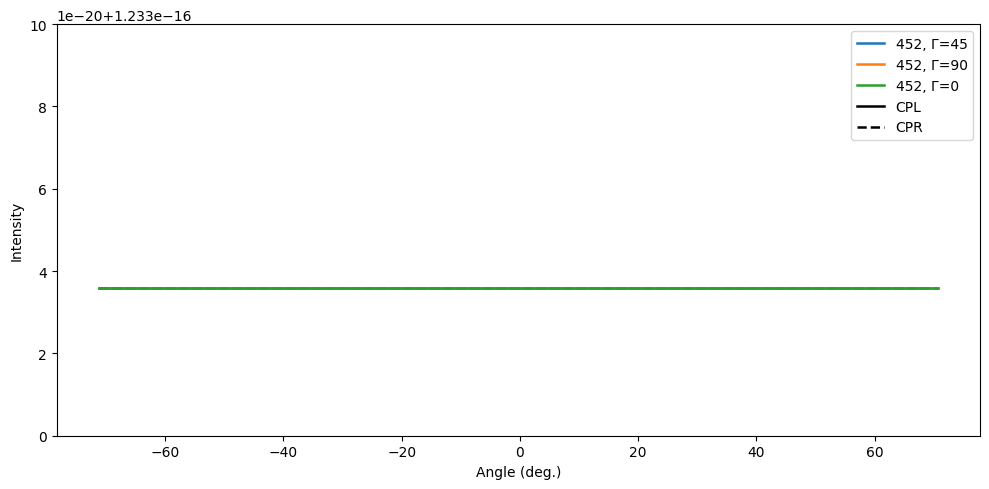

In [49]:
plot_neg_pos_comparison(all_samples, "energy_neg", "energy_pos", out_dir="plots")


Generating plots …


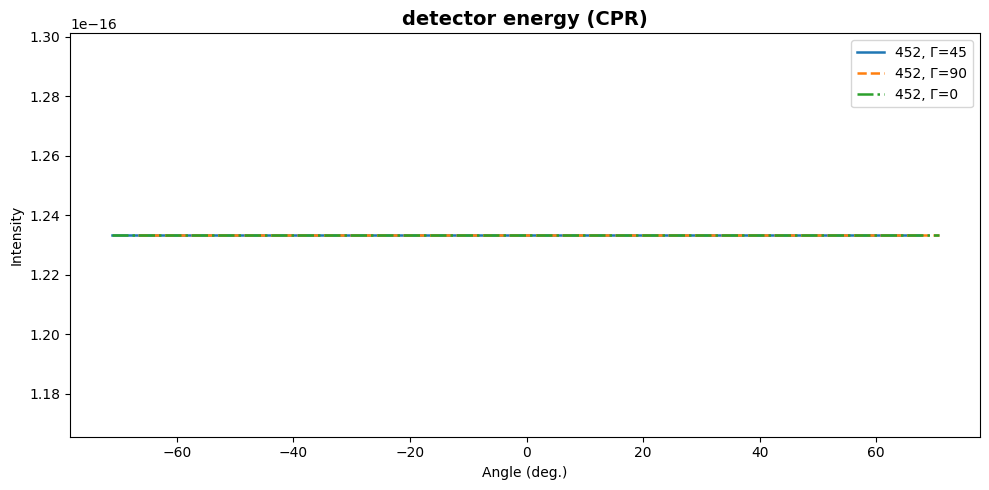

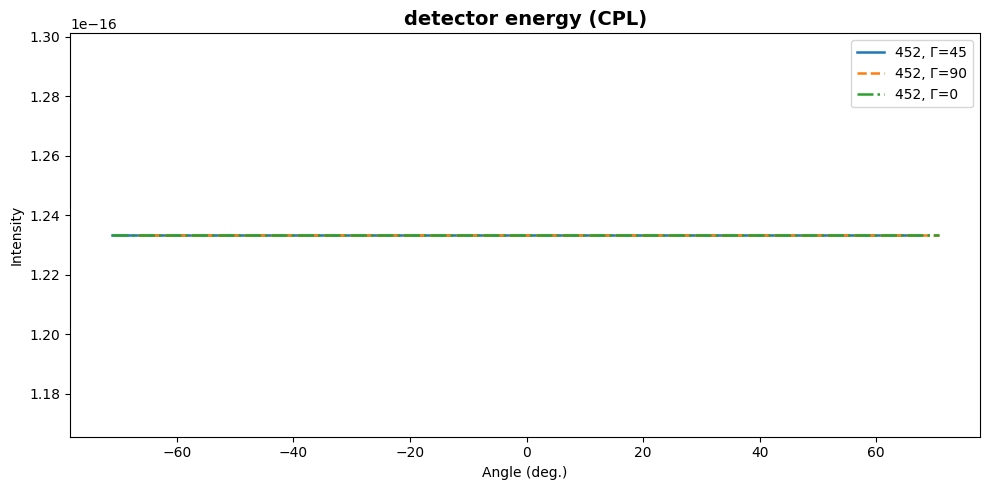

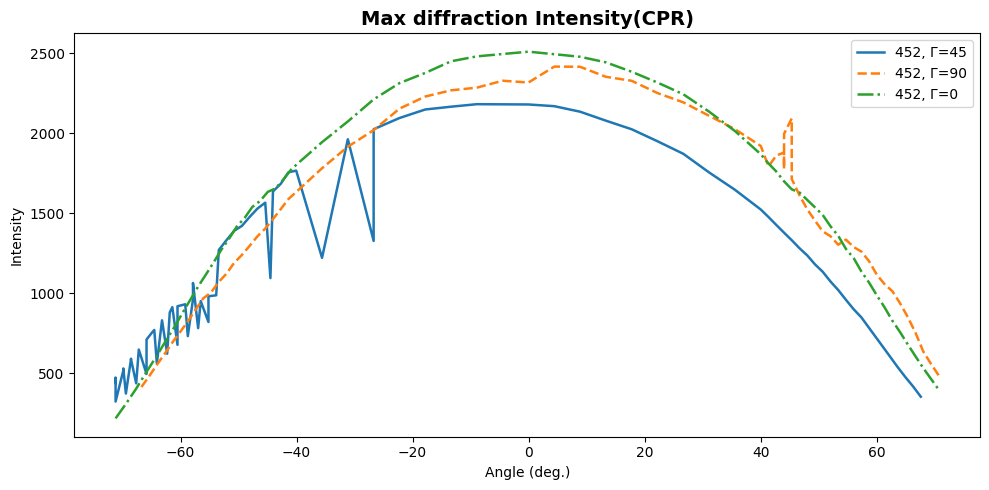

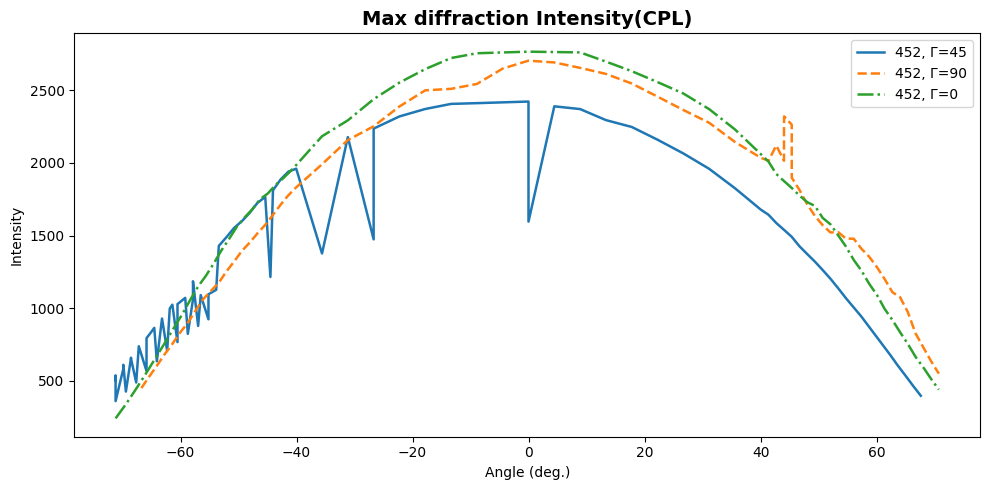

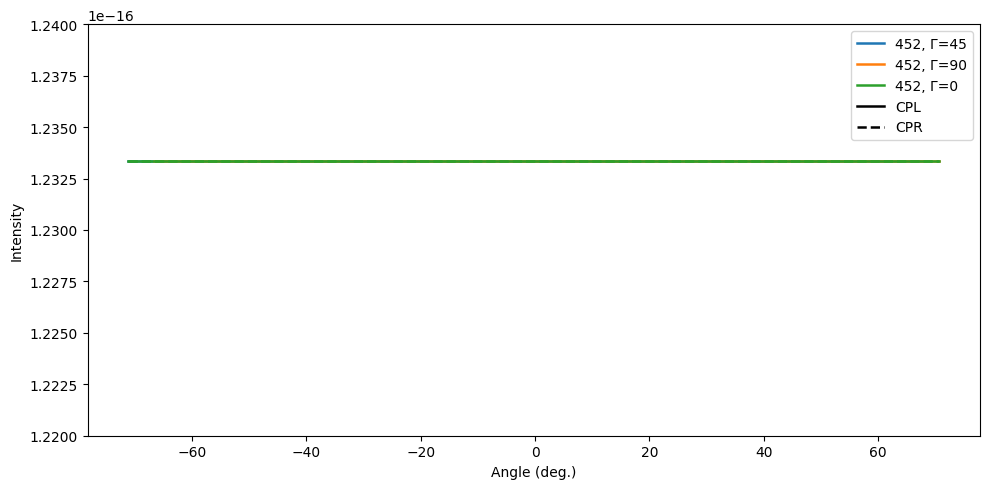

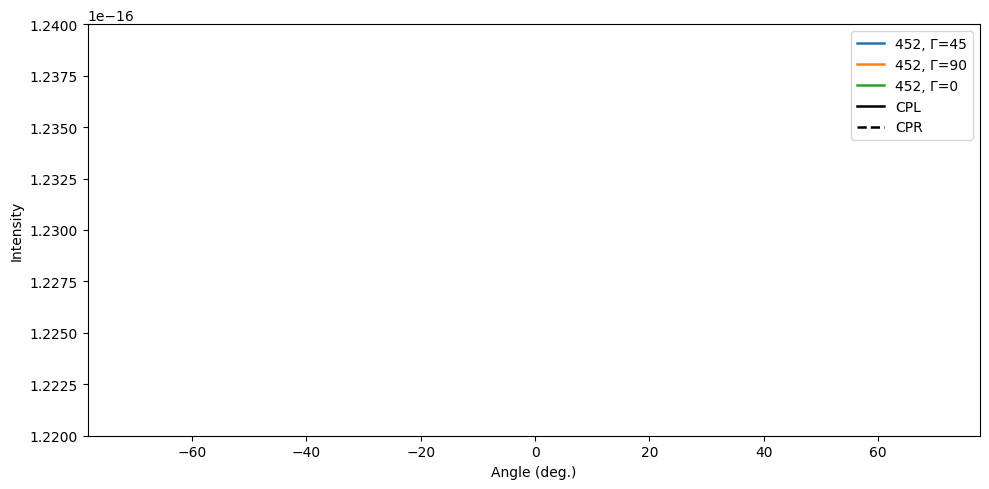

In [39]:
# ── Generate all comparison plots ────────────────────────────────────────────
print("\nGenerating plots …")
for key in file_keys:
    plot_comparison(all_samples, key, plot_meta[key])

# Dedicated neg/pos overlay plot
plot_neg_pos_comparison(all_samples, "energy_neg", "energy_pos", out_dir="plots")
plot_neg_pos_comparison(all_samples, "max_avg_diff_neg", "max_avg_diff_pos", out_dir="plots")

